In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/telco.csv")   # path relative to notebooks/

print(df.shape)
df.head()


(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
blank = df[df["TotalCharges"].str.strip() == ""]
print(len(blank))
blank[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]


11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].dtype, df["TotalCharges"].isna().sum())


float64 11


In [5]:
df = df.drop(columns="customerID")
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print(df["Churn"].value_counts())
print(df["Churn"].mean())      # churn rate


Churn
0    5174
1    1869
Name: count, dtype: int64
0.2653698707936959


In [6]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["Churn"]]
print(len(num_cols), len(cat_cols))


3 16


In [7]:
for c in cat_cols:
    print(c, df[c].unique())


gender <StringArray>
['Female', 'Male']
Length: 2, dtype: str
SeniorCitizen [0 1]
Partner <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents <StringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingMovies <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Contract <StringArray>
['Month-to-month', 'One y

In [8]:
import matplotlib.pyplot as plt

overall = df["Churn"].mean()

def churn_rate_bar(ax, col):
    stats = df.groupby(col)["Churn"].agg(["mean", "count"]).sort_values("mean")
    ax.barh(stats.index.astype(str), stats["mean"])
    ax.axvline(overall, color="gray", ls="--", label=f"overall {overall:.0%}")
    for i, (rate, n) in enumerate(zip(stats["mean"], stats["count"])):
        ax.text(rate, i, f" {rate:.0%} (n={n})", va="center", fontsize=8)
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlim(0, 1)
    ax.legend(loc="lower right", fontsize=8)


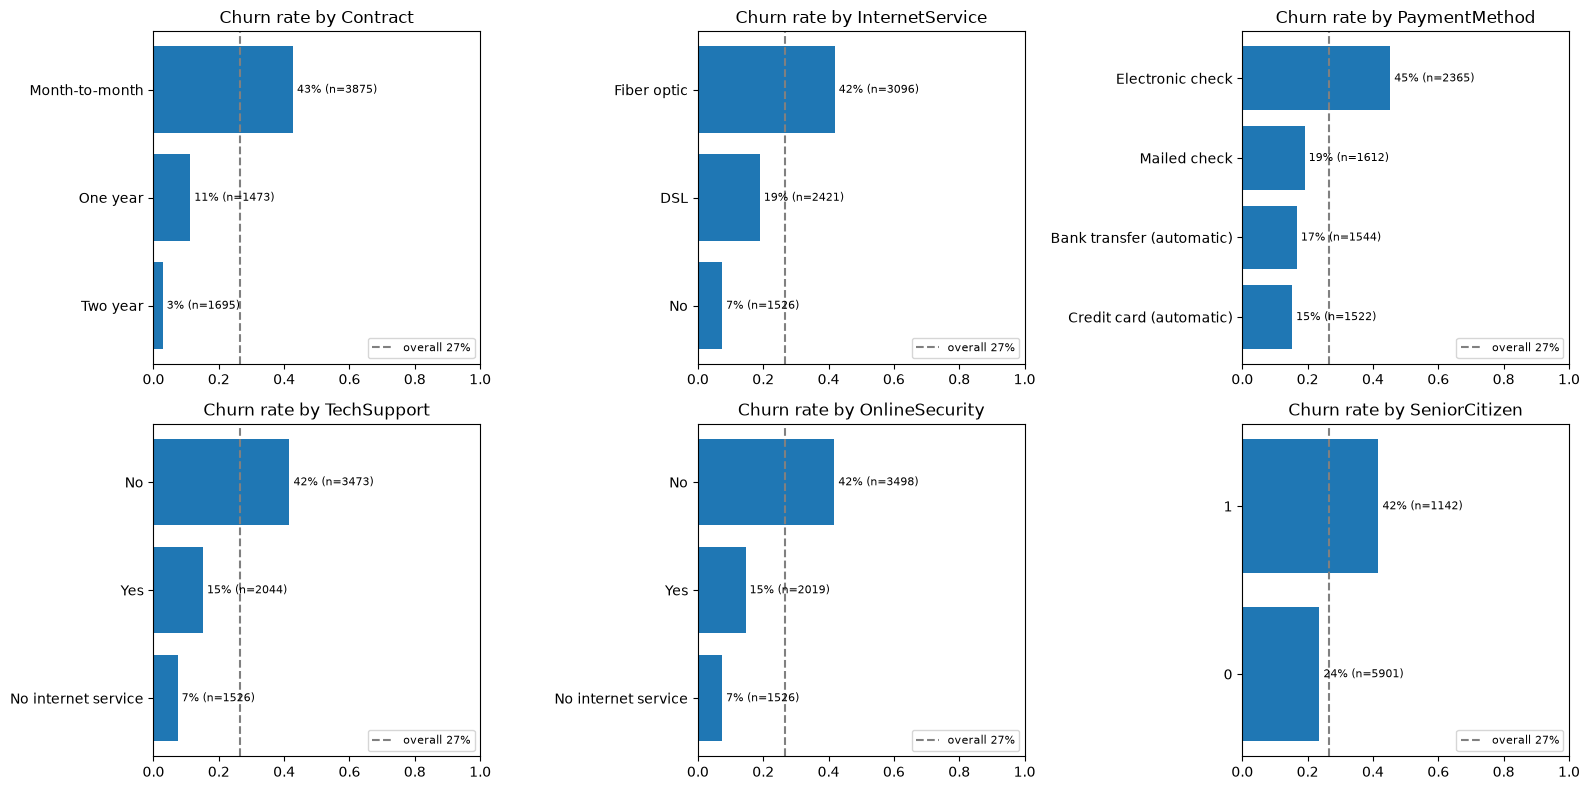

In [9]:
cols = ["Contract", "InternetService", "PaymentMethod",
        "TechSupport", "OnlineSecurity", "SeniorCitizen"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, cols):
    churn_rate_bar(ax, col)
fig.tight_layout()
plt.show()


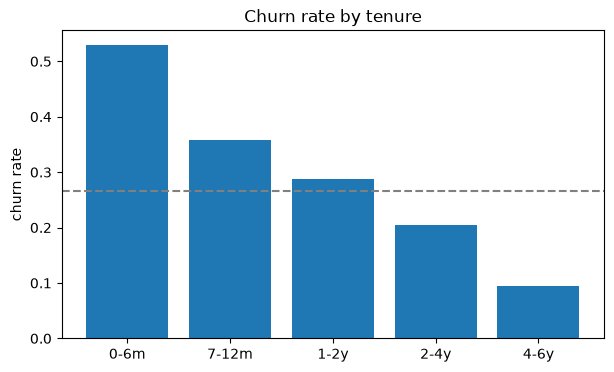

In [10]:
df["tenure_bin"] = pd.cut(df["tenure"], bins=[0, 6, 12, 24, 48, 72],
                          labels=["0-6m", "7-12m", "1-2y", "2-4y", "4-6y"],
                          include_lowest=True)

fig, ax = plt.subplots(figsize=(7, 4))
rate = df.groupby("tenure_bin", observed=True)["Churn"].mean()
ax.bar(rate.index.astype(str), rate.values)
ax.axhline(overall, color="gray", ls="--")
ax.set_title("Churn rate by tenure")
ax.set_ylabel("churn rate")
plt.show()


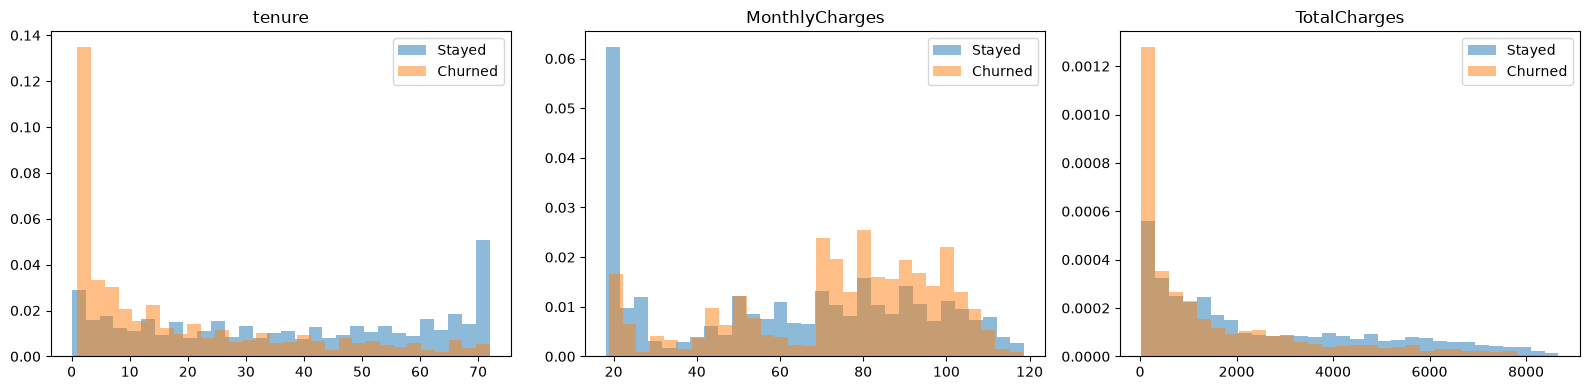

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    for label, name in [(0, "Stayed"), (1, "Churned")]:
        ax.hist(df.loc[df["Churn"] == label, col].dropna(),
                bins=30, alpha=0.5, density=True, label=name)
    ax.set_title(col)
    ax.legend()
fig.tight_layout()
plt.show()


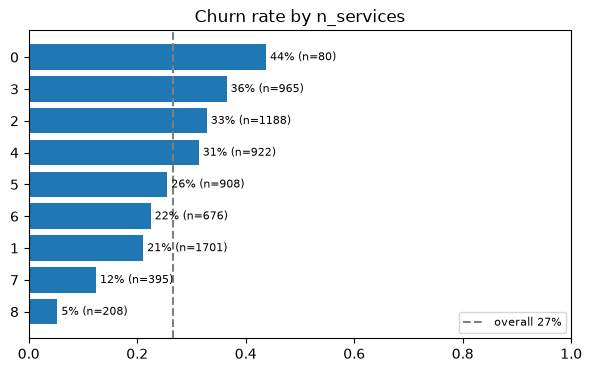

In [12]:
services = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

df["n_services"] = (df[services] == "Yes").sum(axis=1)

fig, ax = plt.subplots(figsize=(7, 4))
churn_rate_bar(ax, "n_services")
plt.show()


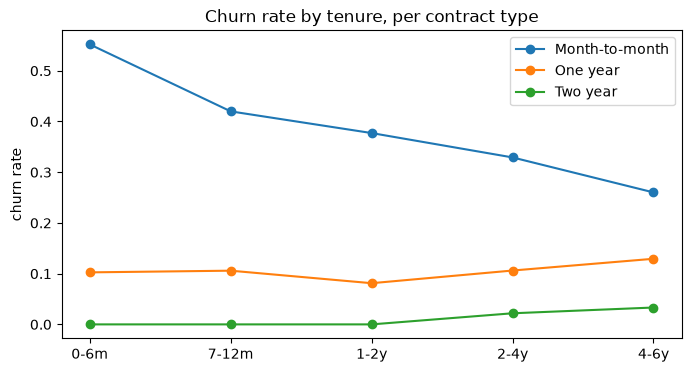

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
for contract, grp in df.groupby("Contract"):
    rate = grp.groupby("tenure_bin", observed=True)["Churn"].mean()
    ax.plot(rate.index.astype(str), rate.values, marker="o", label=contract)
ax.set_title("Churn rate by tenure, per contract type")
ax.set_ylabel("churn rate")
ax.legend()
plt.show()


In [ ]:
~